In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt

import torch
import torchvision
from torchvision import models, transforms, datasets

import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Hyper-parameters
* Hyper-parameters suggested by the original paper

In [2]:
bs=1 # suggested by the paper
lr=0.0002 
beta1=0.5
beta2=0.999
NUM_EPOCHS = 200
ngpu = 1
L1_lambda = 100

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Import  Dataset and load them into batches

In [3]:
data_dir = "maps"

data_transform = transforms.Compose([
    transforms.Resize((256, 512)),
    transforms.CenterCrop((256, 512)),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

dataset_train = datasets.ImageFolder(root=os.path.join(data_dir, "train"), transform=data_transform)
dataset_val = datasets.ImageFolder(root=os.path.join(data_dir, "val"), transform=data_transform)

dataloader_train = torch.utils.data.DataLoader(dataset_train, batch_size=bs, shuffle=True, num_workers=0)
dataloader_val = torch.utils.data.DataLoader(dataset_val, batch_size=24, shuffle=True, num_workers=0)

In [4]:
print(len(dataset_train))
print(len(dataset_val))

1096
1098


# Define function to show image

In [5]:
def show_image(img, title="No title", figsize=(5,5)):
    img = img.numpy().transpose(1,2,0)
    mean = np.array([0.5, 0.5, 0.5])
    std = np.array([0.5, 0.5, 0.5])
    
    img = img * std + mean
    np.clip(img, 0, 1)
    
    plt.figure(figsize=figsize)
    plt.imshow(img)
    plt.title(title)

In [6]:
images,_ = next(iter(dataloader_train))

sample_sat = images[0][:,:,:256]
sample_map = images[0][:,:,256:]

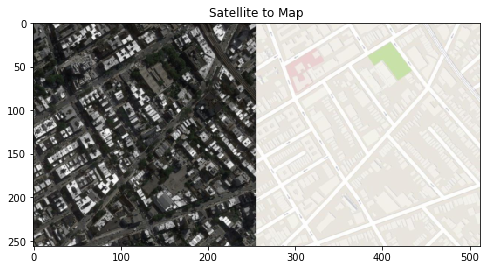

In [7]:
show_image(images[0], title="Satellite to Map", figsize=(8,8))

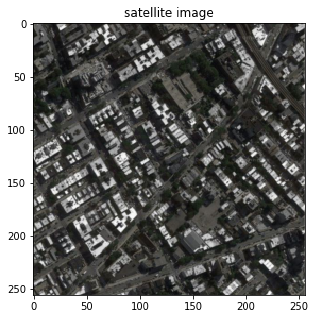

In [8]:
show_image(img = sample_sat, title = "satellite image", figsize=(5,5))

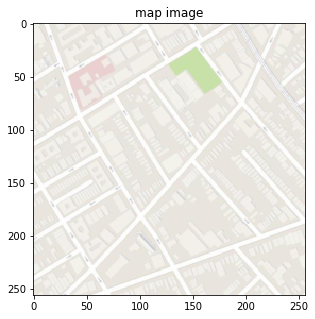

In [9]:
show_image(img = sample_map, title = "map image", figsize=(5, 5))

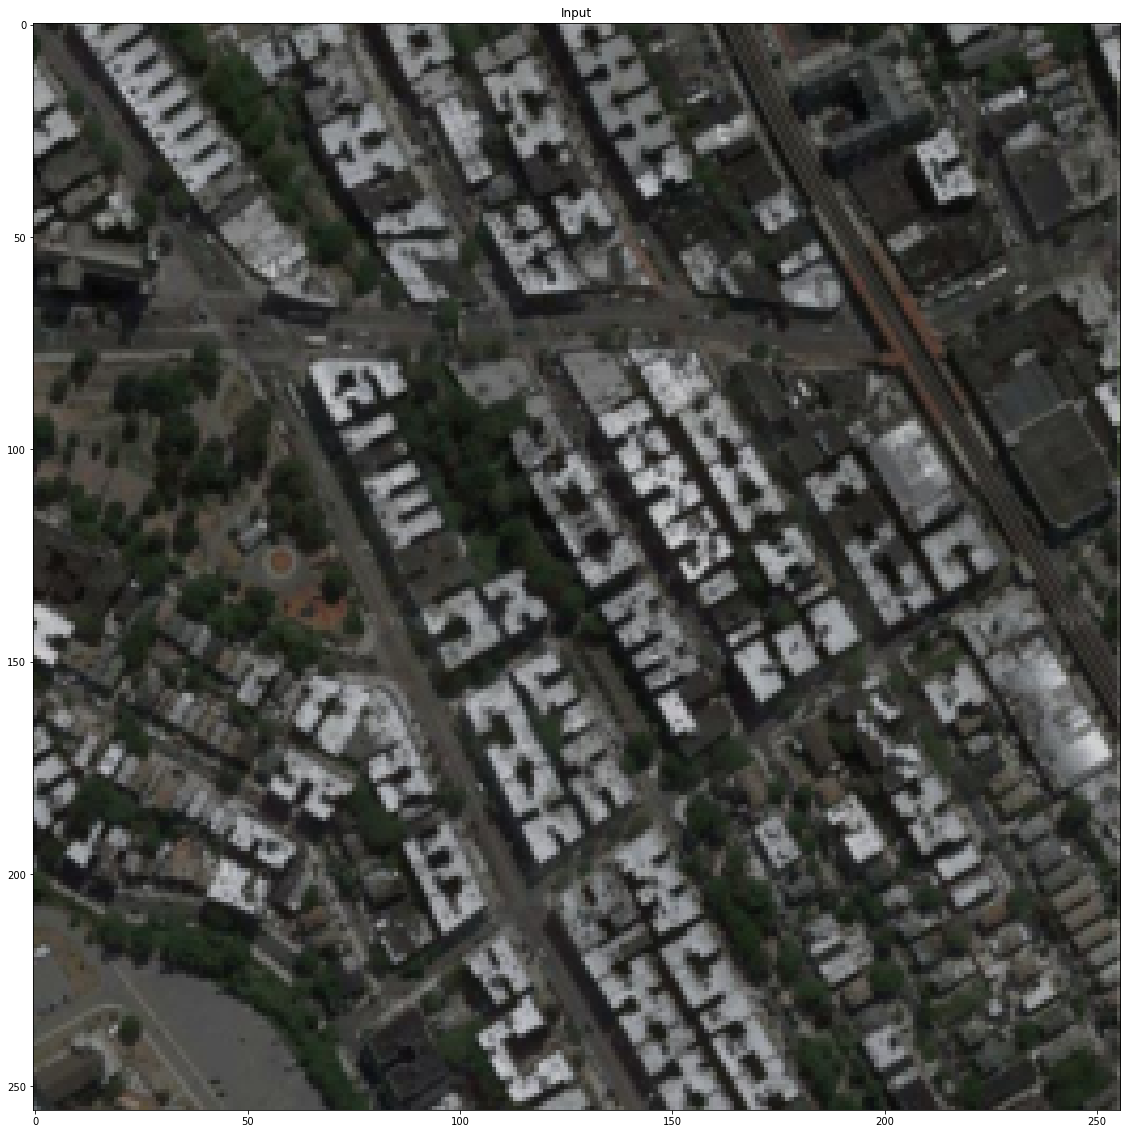

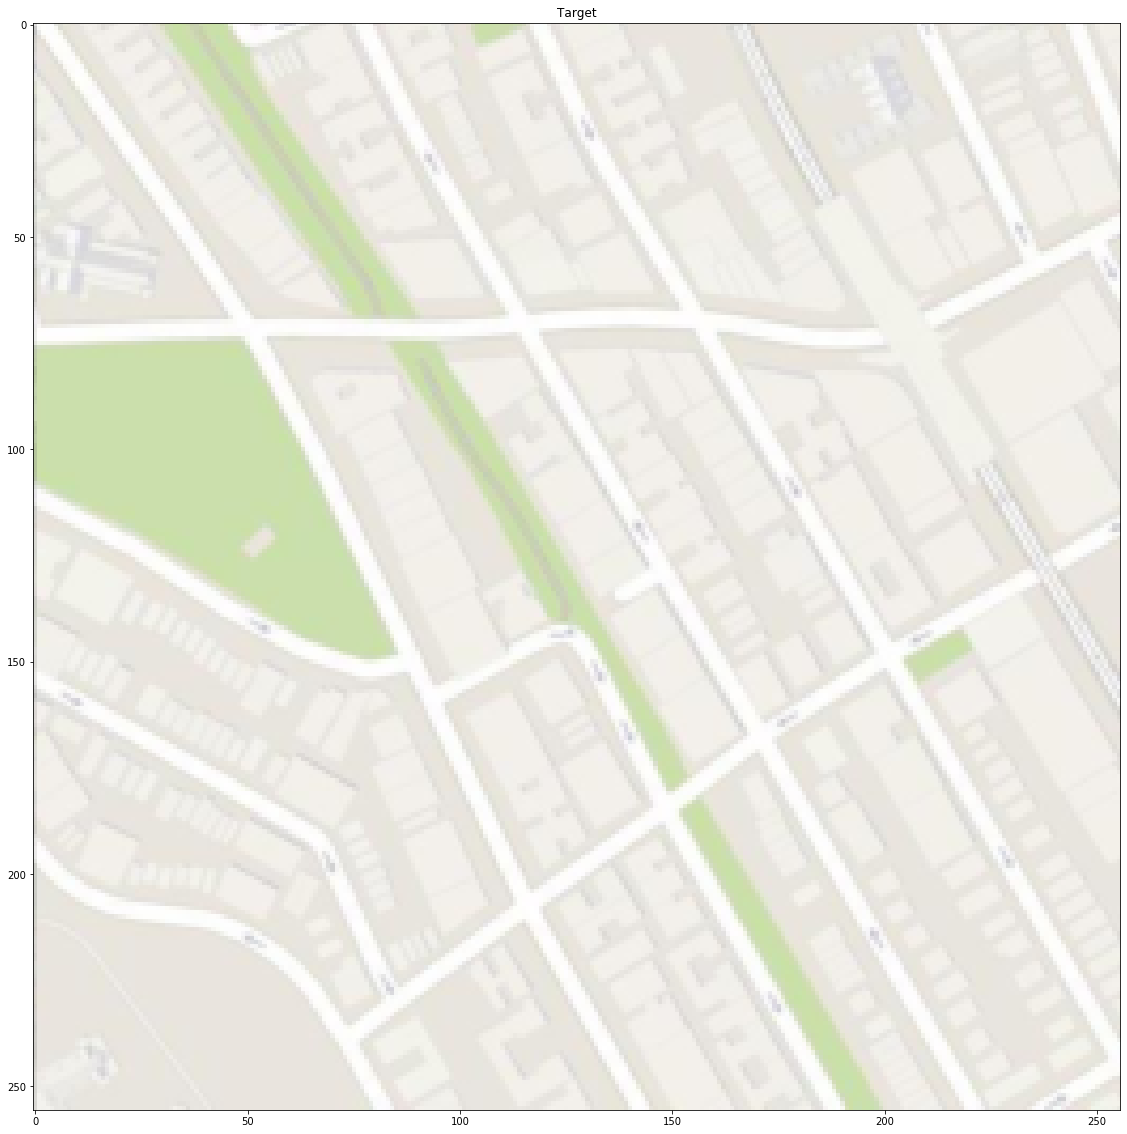

In [11]:
images,_ = next(iter(dataloader_train))
x = torchvision.utils.make_grid(images[:,:,:,:256], padding=10)
y = torchvision.utils.make_grid(images[:,:,:,256:], padding=10)

show_image(x, title="Input", figsize=(20,20))
show_image(y, title="Target", figsize=(20,20))

# Function to initialize model's weights

In [13]:
def weights_init(m):
    name = m.__class__.__name__
    
    if(name.find("Conv") > -1):
        nn.init.normal_(m.weight.data, 0.0, 0.02) # ~N(mean=0.0, std=0.02)
    elif(name.find("BatchNorm") > -1):
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0.0)

# 1.1 Generator - Architecture
* The architecture is U-Net 256

* In 3 x 256 x 256 - Encoder C64 - C128 - C256 - C512 - C512 - C512
- C512 (Latent space)
* Decoder DC1024 - DC1024 - DC1024 - DC512 - DC256 - DC128 - Out 3 x 256 x 256
* Reference: https://arxiv.org/pdf/1505.04597.pdf

In [14]:
"""
    The Generator is a U-Net 256 with skip connections between Encoder and Decoder
"""

class Generator(nn.Module):
    def __init__(self, ngpu):
        super(Generator, self).__init__()
        self.ngpu = ngpu
        
        """
        ===== Encoder ======
        
        * Encoder has the following architecture:
        0) Inp3 
        1) C64 
        2) Leaky, C128, Norm 
        3) Leaky, C256, Norm 
        4) Leaky, C512, Norm 
        5) Leaky, C512, Norm 
        6) Leaky, C512, Norm 
        7) Leaky, C512
        
        * The structure of 1 encoder block is:
        1) LeakyReLU(prev layer)
        2) Conv2D
        3) BatchNorm
        
        Where Conv2D has kernel_size-4, stride=2, padding=1 for all layers
        """
        self.encoder1 = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=4, stride=2, padding=1, bias=False)
        
        self.encoder2 = nn.Sequential(
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128)
        )
        
        self.encoder3 = nn.Sequential(
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
        )
        
        self.encoder4 = nn.Sequential(
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(in_channels=256, out_channels=512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512)
        )
        
        self.encoder5 = nn.Sequential(
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512)
        )
        
        self.encoder6 = nn.Sequential(
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512)
        )
        
        self.encoder7 = nn.Sequential(
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=4, stride=2, padding=1, bias=False)
        )
        
        """
        ===== Decoder =====
        * Decoder has the following architecture:
        1) ReLU(from latent space), DC512, Norm, Drop 0.5 - Residual
        2) ReLU, DC512, Norm, Drop 0.5, Residual
        3) ReLU, DC512, Norm, Drop 0.5, Residual
        4) ReLU, DC256, Norm, Residual
        5) ReLU, DC128, Norm, Residual
        6) ReLU, DC64, Norm, Residual
        7) ReLU, DC3, Tanh()
        
        * Note: only apply Dropout in the first 3 Decoder layers
        
        * The structure of each Decoder block is:
        1) ReLU(from prev layer)
        2) ConvTranspose2D
        3) BatchNorm
        4) Dropout
        5) Skip connection
        
        Where ConvTranpose2D has kernel_size=4, stride=2, padding=1
        """
        self.decoder1 = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=512, out_channels=512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.Dropout(0.5)
        )
        # skip connection in forward()
        
        self.decoder2 = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=512*2, out_channels=512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.Dropout(0.5)
        )
        # skip connection in forward()
        
        self.decoder3 = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=512*2, out_channels=512, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.Dropout(0.5)
        )
        # skip connection in forward()
        
        self.decoder4 = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=512*2, out_channels=256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            #nn.Dropout(0.5)
        )
        
        self.decoder5 = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=256*2, out_channels=128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            #nn.Dropout(0.5)
        )
        
        self.decoder6 = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=128*2, out_channels=64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            #nn.Dropout(0.5)
        )
        
        self.decoder7 = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(in_channels=64*2, out_channels=3, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
        )
    
    def forward(self, x):
        e1 = self.encoder1(x)
        e2 = self.encoder2(e1)
        e3 = self.encoder3(e2)
        e4 = self.encoder4(e3)
        e5 = self.encoder5(e4)
        e6 = self.encoder6(e5)
        
        latent_space = self.encoder7(e6)
        
        d1 = torch.cat([self.decoder1(latent_space), e6], dim=1)
        d2 = torch.cat([self.decoder2(d1), e5], dim=1)
        d3 = torch.cat([self.decoder3(d2), e4], dim=1)
        d4 = torch.cat([self.decoder4(d3), e3], dim=1)
        d5 = torch.cat([self.decoder5(d4), e2], dim=1)
        d6 = torch.cat([self.decoder6(d5), e1], dim=1)
        
        out = self.decoder7(d6)
        
        return out

# 1.2 Generator - Initialization

In [16]:
model_G = Generator(ngpu=1)

if(device == "cuda" and ngpu > 1):
    model_G = nn.DataParallel(model_G, list(range(ngpu)))
    
model_G.apply(weights_init)
model_G.to(device)

Generator(
  (encoder1): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (encoder2): Sequential(
    (0): LeakyReLU(negative_slope=0.2, inplace=True)
    (1): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (encoder3): Sequential(
    (0): LeakyReLU(negative_slope=0.2, inplace=True)
    (1): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (encoder4): Sequential(
    (0): LeakyReLU(negative_slope=0.2, inplace=True)
    (1): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (encoder5): Sequential(
    (0): LeakyReLU(negative_slope=0.2, inplace=True)
    (1): Conv2d(512, 512, kernel_s

In [18]:
model_G.to(device)
#model_G(images[:,:,:,:256]).shape

Generator(
  (encoder1): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
  (encoder2): Sequential(
    (0): LeakyReLU(negative_slope=0.2, inplace=True)
    (1): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (encoder3): Sequential(
    (0): LeakyReLU(negative_slope=0.2, inplace=True)
    (1): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (2): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (encoder4): Sequential(
    (0): LeakyReLU(negative_slope=0.2, inplace=True)
    (1): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (encoder5): Sequential(
    (0): LeakyReLU(negative_slope=0.2, inplace=True)
    (1): Conv2d(512, 512, kernel_s

# 2.1 Discriminator - Architecture
* PatchGan Discriminator with receptive field of each patch is **rf = 70x70**
* Structure is **C64 (no norm, 4,2,1)-C128 (4,2,1)-C256 (4,2,1)-C512 (4,1,1) - Channel 1 (4,1,1)**, where C is Convolution - BatchNorm - LeakyReLU
* Activations are **LeakyReLU(0.2)**
* BatchNorm is applied to all layers but C64
* Last 2 layers has **kernel_size=4, stride=1, padding=1**

In [19]:
class Discriminator(nn.Module):
    def __init__(self, ngpu):
        super(Discriminator, self).__init__()
        self.ngpu = ngpu
        
        self.structure = nn.Sequential(
            nn.Conv2d(in_channels=3*2, out_channels=64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(in_channels=64, out_channels= 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(in_channels=256, out_channels=512, kernel_size=4, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            
            nn.Conv2d(in_channels=512, out_channels=1, kernel_size=4, stride=1, padding=1, bias=False),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        return self.structure(x)

# 2.2 Discriminator Initialization

In [17]:
model_D = Discriminator(ngpu=1)

if(device == "cuda" and ngpu>1):
    model_D = torch.DataParallel(model_D, list(rang(ngpu)))
    
model_D.apply(weights_init)
model_D.to(device)

Discriminator(
  (structure): Sequential(
    (0): Conv2d(6, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1), padding=(1, 1), bias=False)
    (12): Sigmoid()
  )
)

In [39]:
out1 = model_D(torch.cat([images[:,:,:,:256].to(device), images[:,:,:,256:].to(device)], dim=1)).to(device)
out2 = torch.ones(size=out1.shape, dtype=torch.float, device=device)

print(out1.shape)
print(criterion(out1, out2))

torch.Size([1, 1, 30, 30])
tensor(0.7781, device='cuda:0', grad_fn=<BinaryCrossEntropyBackward>)


# 3. Training process
* We train Generator 2 times for each time we train Discriminator

* Let $x$ be the input satellite image and $y$ be the ground-truth map image. The objective is to train the U-Net Generator $G$ so that it can translate satellite image to a map image as realistic as possible.

In [18]:
criterion = nn.BCELoss()

optimizerD = optim.Adam(model_D.parameters(), lr=lr, betas=(beta1, beta2))
optimizerG = optim.Adam(model_G.parameters(), lr=lr, betas=(beta1, beta2))

NUM_EPOCHS=171
model_D.to(device)
model_G.to(device)
print()

In [29]:
L1_lambda = 100
NUM_EPOCHS= 50

In [31]:
for epoch in range(NUM_EPOCHS+1):
    print(f"Training epoch {epoch+1}")
    for images,_ in iter(dataloader_train):
        # ========= Train Discriminator ===========
        # Train on real data
        # Maximize log(D(x,y)) <- maximize D(x,y)
        model_D.zero_grad()
        
        inputs = images[:,:,:,:256].to(device) # input image data
        targets = images[:,:,:,256:].to(device) # real targets data
        
        real_data = torch.cat([inputs, targets], dim=1).to(device)
        outputs = model_D(real_data) # label "real" data
        labels = torch.ones(size = outputs.shape, dtype=torch.float, device=device)
        
        lossD_real = 0.5 * criterion(outputs, labels) # divide the objective by 2 -> slow down D
        lossD_real.backward()
        
        # Train on fake data
        # Maximize log(1-D(x,G(x))) <- minimize D(x,G(x))
        gens = model_G(inputs).detach()
         
        fake_data = torch.cat([inputs, gens], dim=1) # generated image data
        outputs = model_D(fake_data)
        labels = torch.zeros(size = outputs.shape, dtype=torch.float, device=device) # label "fake" data
        
        lossD_fake = 0.5 * criterion(outputs, labels) # divide the objective by 2 -> slow down D
        lossD_fake.backward()
        
        optimizerD.step()
        
        # ========= Train Generator x2 times ============
        # maximize log(D(x, G(x)))
        for i in range(2):
            model_G.zero_grad()
            
            gens = model_G(inputs)
            
            gen_data = torch.cat([inputs, gens], dim=1) # concatenated generated data
            outputs = model_D(gen_data)
            labels = torch.ones(size = outputs.shape, dtype=torch.float, device=device)
            
            lossG = criterion(outputs, labels) + L1_lambda * torch.abs(gens-targets).sum()
            lossG.backward()
            optimizerG.step()
            
    if(epoch%5==0):
        torch.save(model_G, "./sat2mapGen_v1.3.pth")
        torch.save(model_D, "./sat2mapDisc_v1.3.pth")
    
print("Done!")

Training epoch 1
Training epoch 2
Training epoch 3
Training epoch 4
Training epoch 5
Training epoch 6
Training epoch 7
Training epoch 8
Training epoch 9
Training epoch 10
Training epoch 11
Training epoch 12
Training epoch 13
Training epoch 14
Training epoch 15
Training epoch 16
Training epoch 17
Training epoch 18
Training epoch 19
Training epoch 20
Training epoch 21
Training epoch 22
Training epoch 23
Training epoch 24
Training epoch 25
Training epoch 26
Training epoch 27
Training epoch 28
Training epoch 29
Training epoch 30
Training epoch 31
Training epoch 32
Training epoch 33
Training epoch 34
Training epoch 35
Training epoch 36
Training epoch 37
Training epoch 38
Training epoch 39
Training epoch 40
Training epoch 41
Training epoch 42
Training epoch 43
Training epoch 44
Training epoch 45
Training epoch 46
Training epoch 47
Training epoch 48
Training epoch 49
Training epoch 50
Training epoch 51
Done!


# 4. Results

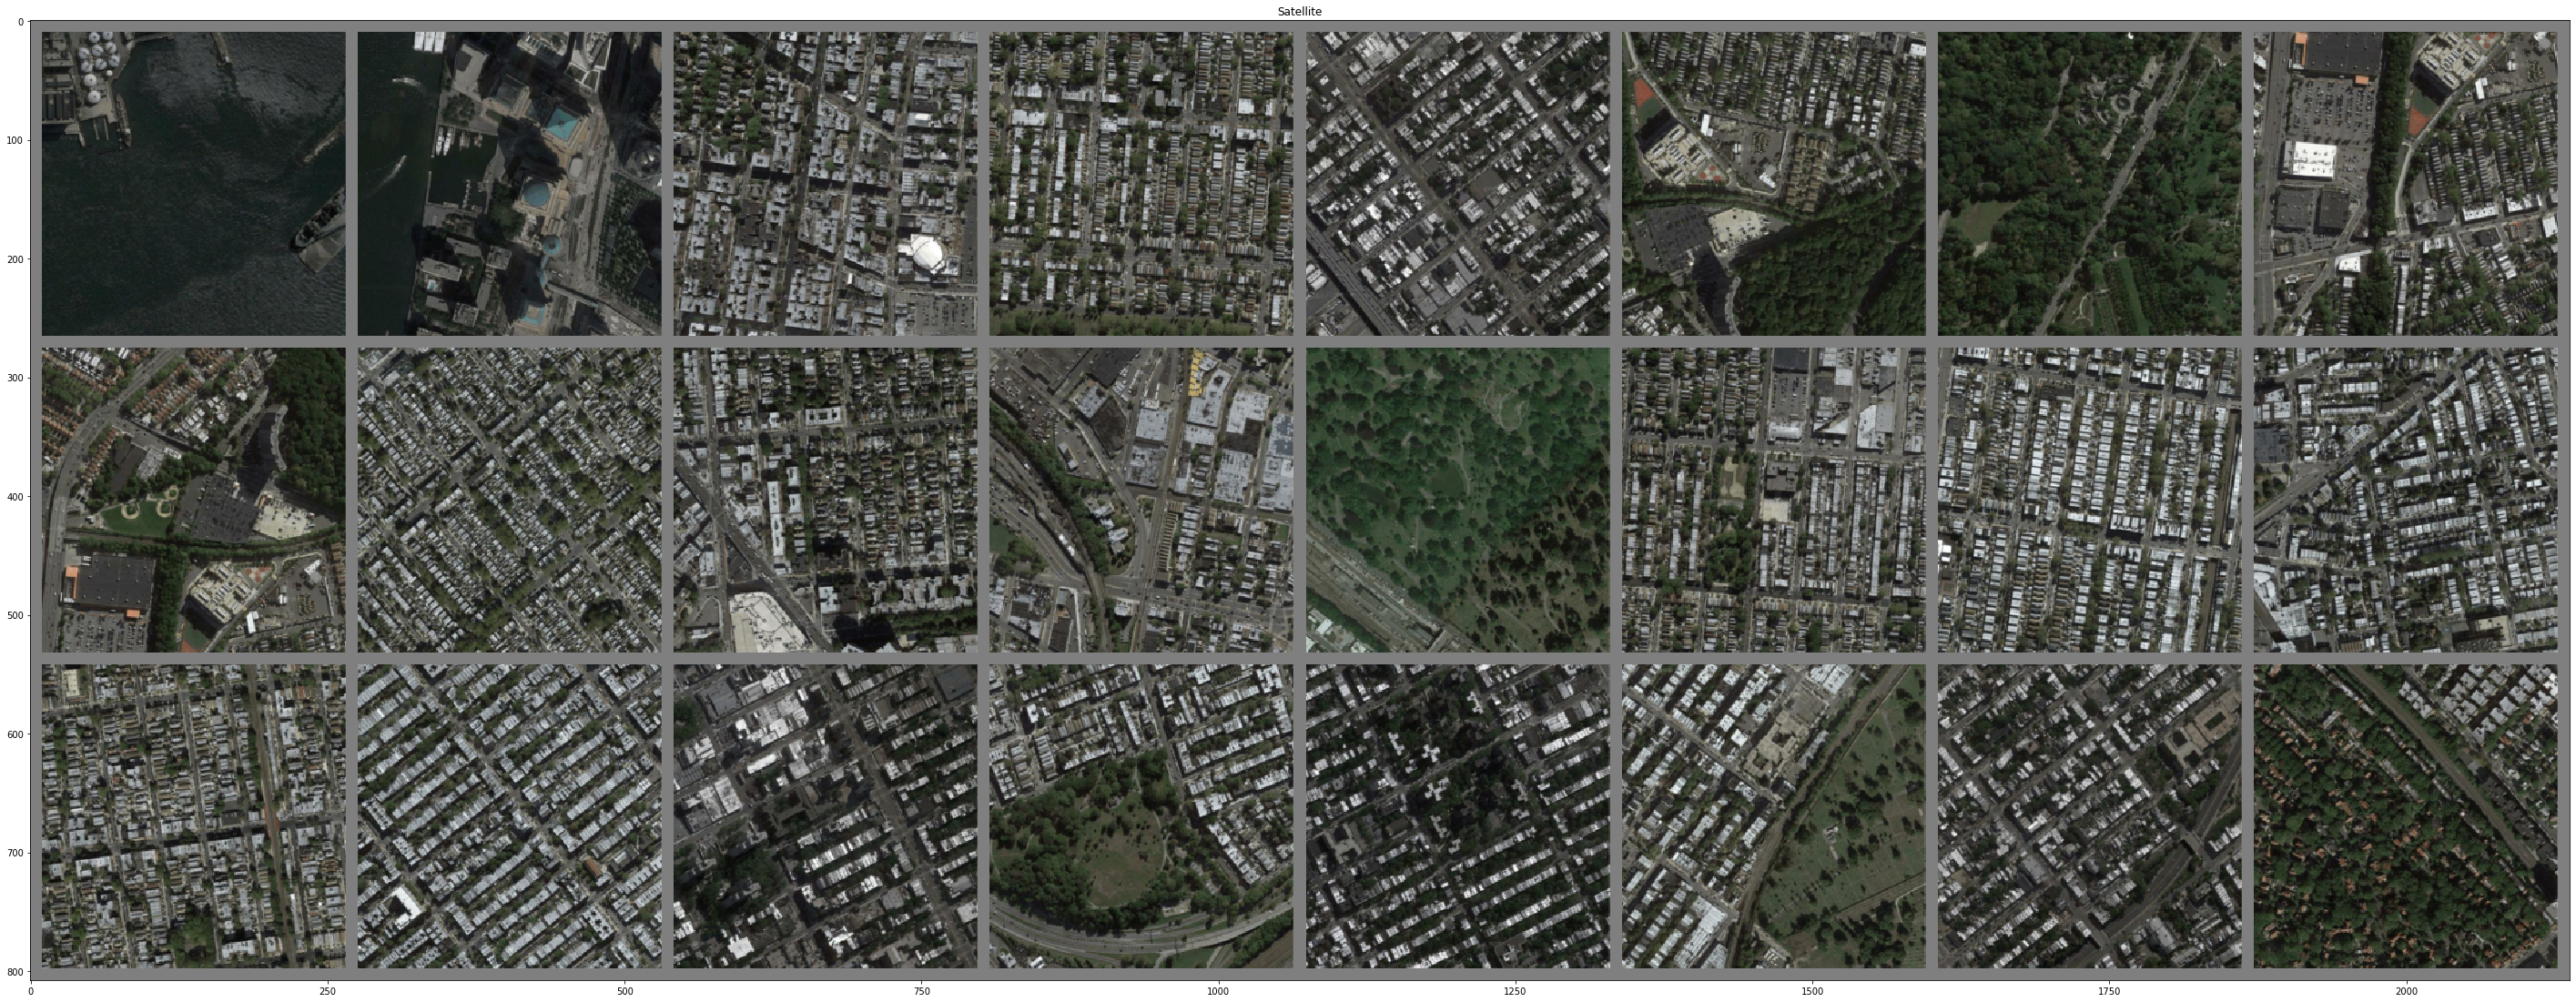

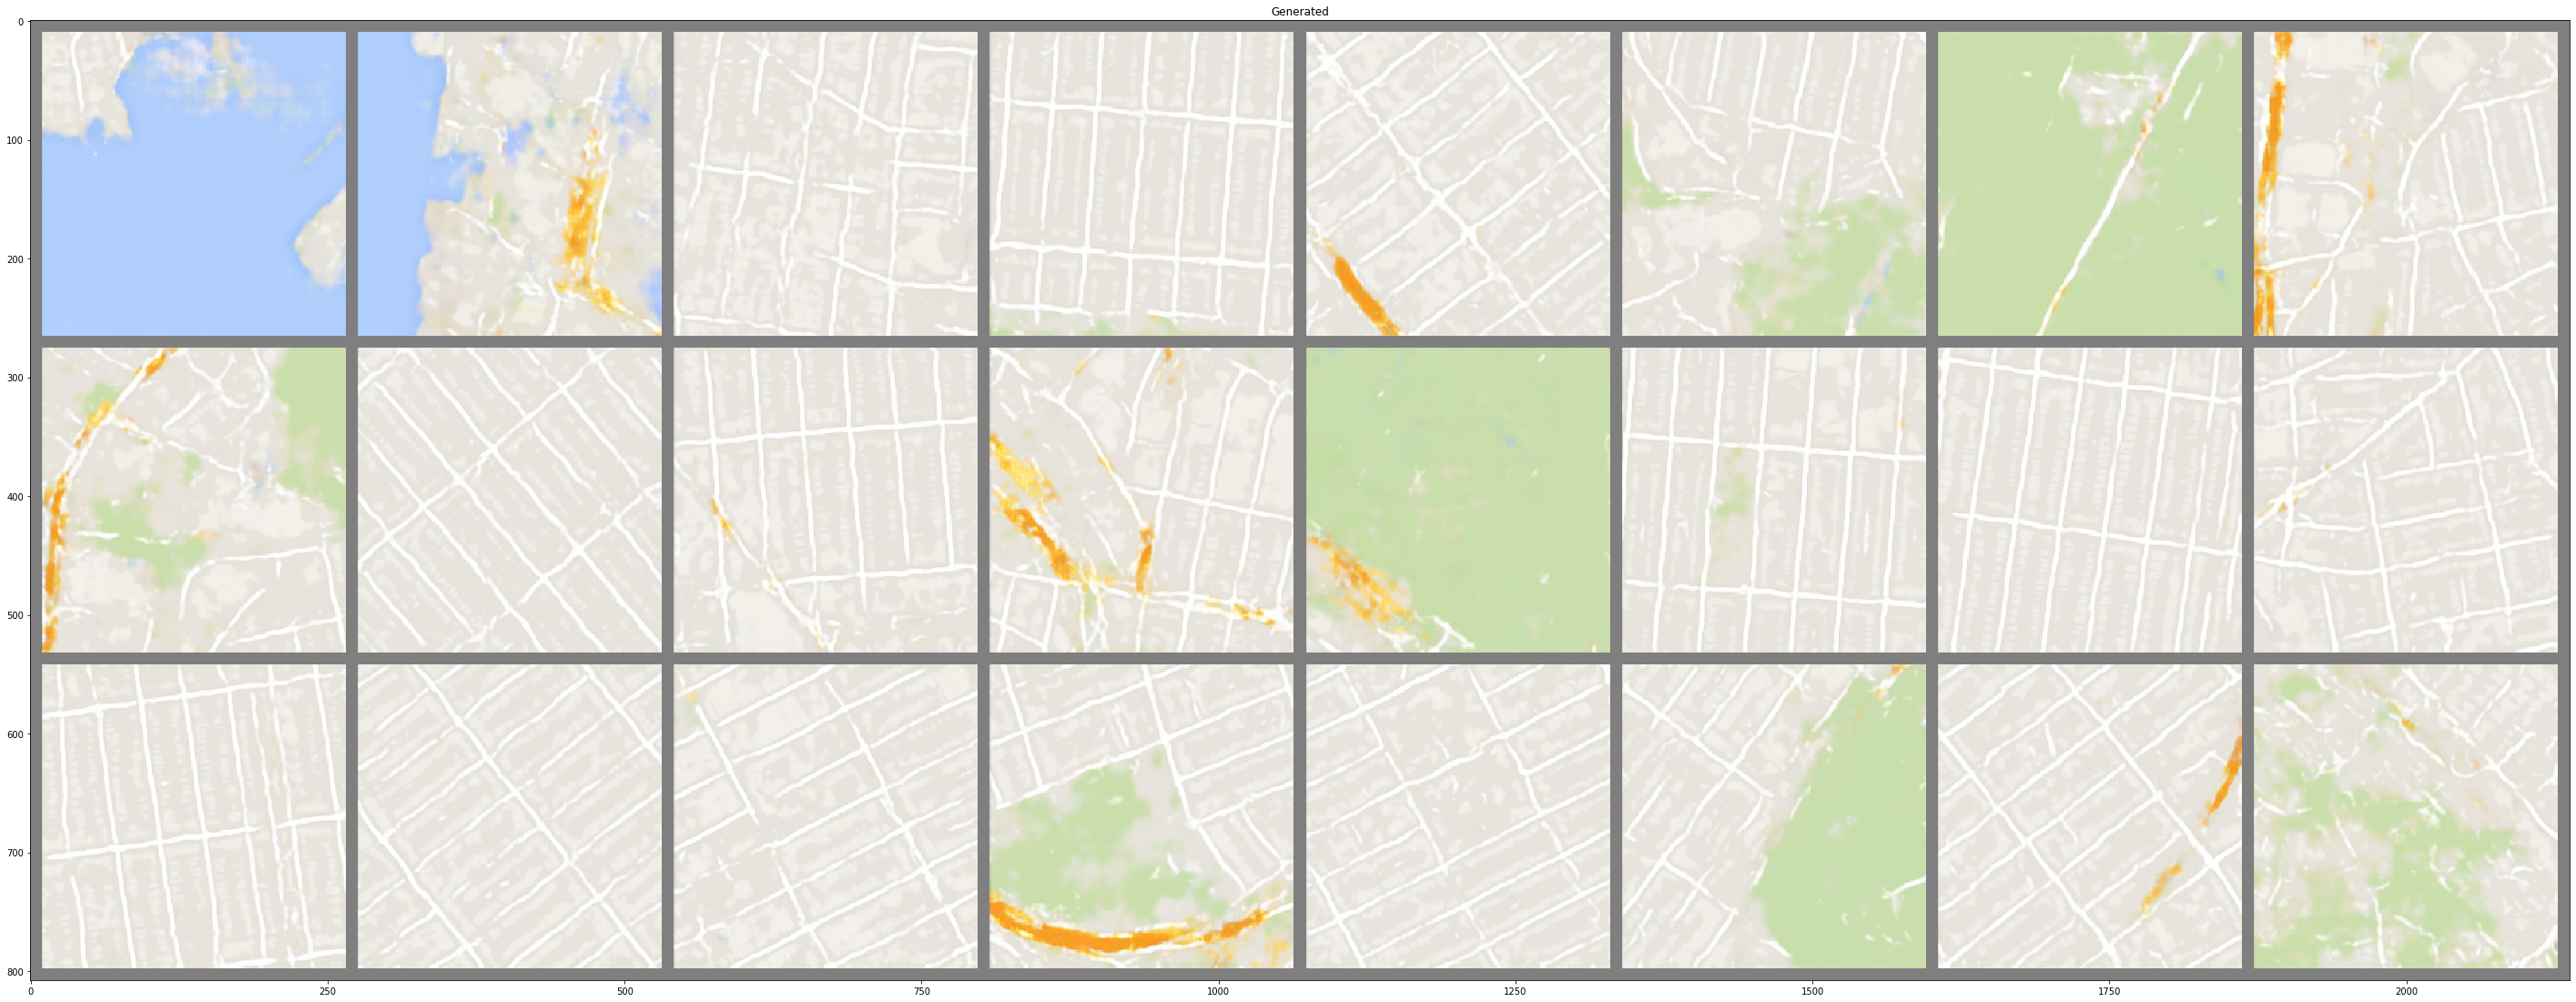

In [24]:
#model_G = torch.load("./sat2mapGen_v1.2.pth")
#model_G.apply(weights_init)
#test_imgs,_ = next(iter(dataloader_val))

satellite = test_imgs[:,:,:,:256].to(device)
maps = test_imgs[:,:,:,256:].to(device)

gen = model_G(satellite)
#gen = gen[0]

satellite = satellite.detach().cpu()
gen = gen.detach().cpu()
maps = maps.detach().cpu()

show_image(torchvision.utils.make_grid(satellite, padding=10), title="Satellite", figsize=(50,50))
show_image(torchvision.utils.make_grid(gen, padding=10), title="Generated", figsize=(50,50))
#show_image(torchvision.utils.make_grid(maps, padding=10), title="Expected Output", figsize=(50,50))

In [170]:
#show_image(maps, title="Expected Output", figsize=(5,5))

torch.Size([16, 3, 256, 512])


In [178]:
#print(model_D(torch.cat([satellite[6,:,:,:].reshape(1,3,256,256).to(device), gen[6,:,:,:].reshape(1,3,256,256).to(device)], dim=1)))

In [179]:
#torch.save(model_G, "./sat2mapGen_v1.1.pth")
#torch.save(model_D, "./sat2mapDisc_v1.1.pth")

In [28]:
model_G = torch.load("./sat2mapGen_v1.1.pth")

# Random Experiment zone (trivial stuffs)

In [17]:
inp = images[:,:,:,:256]
target = images[:,:,:,256:]

print(inp.shape)
print(target.shape)

torch.Size([8, 3, 256, 256])
torch.Size([8, 3, 256, 256])


In [18]:
data_real = torch.cat([inp, target], dim=1)
print(data_real.shape)

torch.Size([8, 6, 256, 256])


In [19]:
transformmm = transforms.Compose([
    transforms.RandomVerticalFlip(p=1),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

In [20]:
datasettt = datasets.ImageFolder(root=os.path.join(data_dir,"train"), transform=transformmm)

In [21]:
dataloaderrrr = torch.utils.data.DataLoader(datasettt, batch_size=1, shuffle=True, num_workers=0)

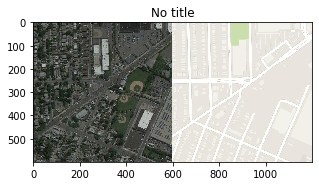

In [22]:
imgsss,_ = next(iter(dataloaderrrr))
show_image(imgsss[0,:,:,:])

In [26]:
name = "TransposeConv2d"
print(name.find("Conv"))

9


In [33]:
a = torch.ones(size=(8,3,5,5))
b = torch.zeros(size=(8,3,5,5))

torch.abs(a-b).sum()

tensor(600.)

Train 200 epochs with $\lambda = 100$ then retrain with $\lambda = 50$